In [1]:
import pandas as pd
import numpy as np

df=pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [2]:
df.info()
df['Class'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Class
0    284315
1       492
Name: count, dtype: int64

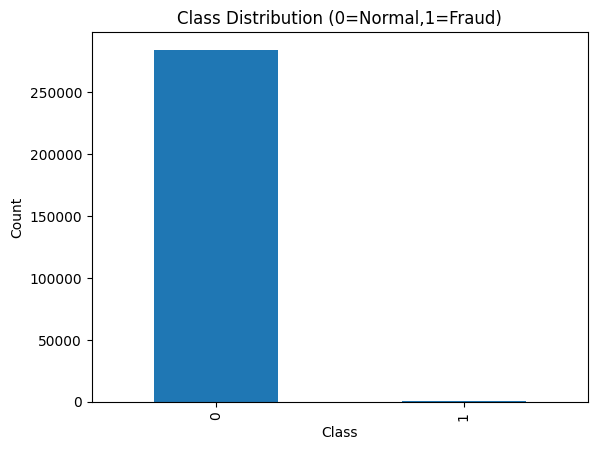

In [4]:
import matplotlib.pyplot as plt

df['Class'].value_counts().plot(kind='bar')
plt.title('Class Distribution (0=Normal,1=Fraud)')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [5]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


In [6]:
from sklearn.model_selection import train_test_split

X=df.drop('Class',axis=1)
Y=df['Class']

X_train,X_test,Y_train,Y_test = train_test_split(
    X,Y,test_size=0.2,random_state=42, stratify=Y
)
print(X_train.shape,X_test.shape)

(227845, 30) (56962, 30)


In [7]:
from imblearn.over_sampling import SMOTE

smote=SMOTE(random_state=42)
X_train_resampled,Y_train_resampled=smote.fit_resample(X_train,Y_train)
print(Y_train_resampled.value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train_resampled)
X_test_scaled=scaler.transform(X_test)

______________

### Models

______________

In [9]:
from sklearn.linear_model import LogisticRegression

log_model=LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled,Y_train_resampled)
Y_pred_log=log_model.predict(X_test_scaled)

In [10]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(Y_test, Y_pred_log))
print(classification_report(Y_test, Y_pred_log))

[[56296   568]
 [   10    88]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.13      0.90      0.23        98

    accuracy                           0.99     56962
   macro avg       0.57      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962



In [11]:
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled,Y_train_resampled)

Y_pred_dt = dt_model.predict(X_test_scaled)

print(confusion_matrix(Y_test, Y_pred_dt))
print(classification_report(Y_test, Y_pred_dt))

[[56758   106]
 [   20    78]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.42      0.80      0.55        98

    accuracy                           1.00     56962
   macro avg       0.71      0.90      0.78     56962
weighted avg       1.00      1.00      1.00     56962



In [12]:
from sklearn.ensemble import RandomForestClassifier

rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(X_train_scaled,Y_train_resampled)

Y_pred_rf=rf_model.predict(X_test_scaled)

print(confusion_matrix(Y_test,Y_pred_rf))
print(classification_report(Y_test,Y_pred_rf))

[[56847    17]
 [   17    81]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.83      0.83        98

    accuracy                           1.00     56962
   macro avg       0.91      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



In [13]:
from xgboost import XGBClassifier

xgb_model=XGBClassifier(random_state=42)
xgb_model.fit(X_train_scaled,Y_train_resampled)

Y_pred_xgb=xgb_model.predict(X_test_scaled)

print(confusion_matrix(Y_test,Y_pred_xgb))
print(classification_report(Y_test,Y_pred_xgb))

[[56844    20]
 [   14    84]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.81      0.86      0.83        98

    accuracy                           1.00     56962
   macro avg       0.90      0.93      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [14]:
from sklearn.neighbors import KNeighborsClassifier

knn_model=KNeighborsClassifier()
knn_model.fit(X_train_scaled,Y_train_resampled)

Y_pred_knn=knn_model.predict(X_test_scaled)

print(confusion_matrix(Y_test, Y_pred_knn))
print(classification_report(Y_test, Y_pred_knn))

[[56770    94]
 [   16    82]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.47      0.84      0.60        98

    accuracy                           1.00     56962
   macro avg       0.73      0.92      0.80     56962
weighted avg       1.00      1.00      1.00     56962



In [15]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, Y_train_resampled)

Y_pred_nb = nb_model.predict(X_test_scaled)

print(confusion_matrix(Y_test, Y_pred_nb))
print(classification_report(Y_test, Y_pred_nb))

[[55459  1405]
 [   12    86]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.88      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.93      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [16]:
from sklearn.neural_network import MLPClassifier

ann_model = MLPClassifier(random_state=42, max_iter=300)
ann_model.fit(X_train_scaled, Y_train_resampled)

Y_pred_ann = ann_model.predict(X_test_scaled)

print(confusion_matrix(Y_test, Y_pred_ann))
print(classification_report(Y_test, Y_pred_ann))

[[56835    29]
 [   20    78]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.73      0.80      0.76        98

    accuracy                           1.00     56962
   macro avg       0.86      0.90      0.88     56962
weighted avg       1.00      1.00      1.00     56962



In [17]:
from sklearn.svm import SVC
import numpy as np

np.random.seed(42)
sample_indices = np.random.choice(len(X_train_scaled), size=20000, replace=False)

X_train_svm_sample = X_train_scaled[sample_indices]
Y_train_svm_sample = Y_train_resampled.values[sample_indices]

svm_model = SVC(random_state=42)
svm_model.fit(X_train_svm_sample, Y_train_svm_sample)

Y_pred_svm = svm_model.predict(X_test_scaled)

print(confusion_matrix(Y_test, Y_pred_svm))
print(classification_report(Y_test, Y_pred_svm))

[[56607   257]
 [   11    87]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.25      0.89      0.39        98

    accuracy                           1.00     56962
   macro avg       0.63      0.94      0.70     56962
weighted avg       1.00      1.00      1.00     56962



In [18]:
models_preds = {
    'Logistic Regression': Y_pred_log,
    'Decision Tree': Y_pred_dt,
    'Random Forest': Y_pred_rf,
    'XGBoost': Y_pred_xgb,
    'KNN': Y_pred_knn,
    'Naive Bayes': Y_pred_nb,
    'ANN': Y_pred_ann,
    'SVM (sample)': Y_pred_svm
}

comparison_df = pd.DataFrame([
    {'Model': name, **classification_report(Y_test, preds, output_dict=True)['1']}
    for name, preds in models_preds.items()
]).sort_values(by='f1-score', ascending=False).reset_index(drop=True)

print(comparison_df[['Model', 'precision', 'recall', 'f1-score']])

                 Model  precision    recall  f1-score
0              XGBoost   0.807692  0.857143  0.831683
1        Random Forest   0.826531  0.826531  0.826531
2                  ANN   0.728972  0.795918  0.760976
3                  KNN   0.465909  0.836735  0.598540
4        Decision Tree   0.423913  0.795918  0.553191
5         SVM (sample)   0.252907  0.887755  0.393665
6  Logistic Regression   0.134146  0.897959  0.233422
7          Naive Bayes   0.057679  0.877551  0.108244


--------------

### Tunning

--------------

In [19]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(random_state=42))
])

param_dist = {
    'xgb__n_estimators': [100, 200, 300],
    'xgb__max_depth': [3, 5, 7, 9],
    'xgb__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'xgb__subsample': [0.7, 0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=10,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, Y_train)

print("Best parameters:", xgb_search.best_params_)
print("Best F1 score:", xgb_search.best_score_)

Best parameters: {'xgb__subsample': 0.8, 'xgb__n_estimators': 300, 'xgb__max_depth': 7, 'xgb__learning_rate': 0.1}
Best F1 score: 0.8330055122507952


In [20]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

pipeline_rf = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('rf', RandomForestClassifier(random_state=42))
])

param_dist_rf = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [None, 10, 20, 30],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    pipeline_rf,
    param_distributions=param_dist_rf,
    n_iter=10,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, Y_train)

print("Best parameters:", rf_search.best_params_)
print("Best F1 score:", rf_search.best_score_)

Best parameters: {'rf__n_estimators': 300, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_depth': 30}
Best F1 score: 0.85065711407588


In [21]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import RandomizedSearchCV

pipeline_log = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('log', LogisticRegression(max_iter=1000))
])

param_dist_log = {
    'log__C': [0.01, 0.1, 1, 10, 100],
    'log__penalty': ['l2'],
    'log__solver': ['lbfgs']
}

log_search = RandomizedSearchCV(pipeline_log, param_distributions=param_dist_log, n_iter=5, scoring='f1', cv=3, random_state=42, n_jobs=-1)
log_search.fit(X_train, Y_train)
print("Best parameters:", log_search.best_params_)
print("Best F1 score:", log_search.best_score_)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear

Best parameters: {'log__solver': 'lbfgs', 'log__penalty': 'l2', 'log__C': 100}
Best F1 score: 0.24526267453194736


In [22]:
from sklearn.tree import DecisionTreeClassifier

pipeline_dt = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42))
])

param_dist_dt = {
    'dt__max_depth': [5, 10, 20, None],
    'dt__min_samples_split': [2, 5, 10],
    'dt__min_samples_leaf': [1, 2, 4]
}

dt_search = RandomizedSearchCV(pipeline_dt, param_distributions=param_dist_dt, n_iter=10, scoring='f1', cv=3, random_state=42, n_jobs=-1)
dt_search.fit(X_train, Y_train)
print("Best parameters:", dt_search.best_params_)
print("Best F1 score:", dt_search.best_score_)

Best parameters: {'dt__min_samples_split': 5, 'dt__min_samples_leaf': 2, 'dt__max_depth': None}
Best F1 score: 0.5650380694283134


In [23]:
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

param_dist_knn = {
    'knn__n_neighbors': [3, 5, 7, 9],
    'knn__weights': ['uniform', 'distance']
}

knn_search = RandomizedSearchCV(pipeline_knn, param_distributions=param_dist_knn, n_iter=5, scoring='f1', cv=3, random_state=42, n_jobs=-1)
knn_search.fit(X_train, Y_train)
print("Best parameters:", knn_search.best_params_)
print("Best F1 score:", knn_search.best_score_)

Best parameters: {'knn__weights': 'distance', 'knn__n_neighbors': 3}
Best F1 score: 0.6609719198504246


In [24]:
from sklearn.naive_bayes import GaussianNB

pipeline_nb = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('nb', GaussianNB())
])

param_dist_nb = {
    'nb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]
}

nb_search = RandomizedSearchCV(pipeline_nb, param_distributions=param_dist_nb, n_iter=4, scoring='f1', cv=3, random_state=42, n_jobs=-1)
nb_search.fit(X_train, Y_train)
print("Best parameters:", nb_search.best_params_)
print("Best F1 score:", nb_search.best_score_)

Best parameters: {'nb__var_smoothing': 1e-07}
Best F1 score: 0.5399890427473691


In [25]:
from sklearn.neural_network import MLPClassifier

pipeline_ann = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('ann', MLPClassifier(random_state=42, max_iter=300))
])

param_dist_ann = {
    'ann__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'ann__alpha': [0.0001, 0.001, 0.01]
}

ann_search = RandomizedSearchCV(pipeline_ann, param_distributions=param_dist_ann, n_iter=5, scoring='f1', cv=3, random_state=42, n_jobs=-1)
ann_search.fit(X_train, Y_train)
print("Best parameters:", ann_search.best_params_)
print("Best F1 score:", ann_search.best_score_)

Best parameters: {'ann__hidden_layer_sizes': (50, 50), 'ann__alpha': 0.001}
Best F1 score: 0.7609929125257593


In [26]:
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import RandomizedSearchCV

# Use a smaller sample of the original (pre-SMOTE) training data for SVM tuning speed
X_train_svm_sample_raw = X_train.sample(n=15000, random_state=42)
Y_train_svm_sample_raw = Y_train.loc[X_train_svm_sample_raw.index]

pipeline_svm = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=42))
])

param_dist_svm = {
    'svm__C': [0.1, 1, 10],
    'svm__kernel': ['rbf', 'linear'],
    'svm__gamma': ['scale', 'auto']
}

svm_search = RandomizedSearchCV(
    pipeline_svm,
    param_distributions=param_dist_svm,
    n_iter=4,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1
)

svm_search.fit(X_train_svm_sample_raw, Y_train_svm_sample_raw)
print("Best parameters:", svm_search.best_params_)
print("Best F1 score:", svm_search.best_score_)

Best parameters: {'svm__kernel': 'rbf', 'svm__gamma': 'auto', 'svm__C': 10}
Best F1 score: 0.44755244755244755


In [27]:
import pandas as pd

tuning_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'ANN', 'KNN', 'Decision Tree', 'SVM', 'Naive Bayes', 'Logistic Regression'],
    'Untuned F1': [0.8265, 0.8317, 0.7610, 0.5985, 0.5532, 0.3937, 0.1082, 0.2334],
    'Tuned F1': [0.8507, 0.8330, 0.7736, 0.6610, 0.5650, 0.4476, 0.5400, 0.2453]
})

tuning_comparison['Improvement'] = tuning_comparison['Tuned F1'] - tuning_comparison['Untuned F1']
tuning_comparison = tuning_comparison.sort_values(by='Tuned F1', ascending=False).reset_index(drop=True)

print(tuning_comparison)

                 Model  Untuned F1  Tuned F1  Improvement
0        Random Forest      0.8265    0.8507       0.0242
1              XGBoost      0.8317    0.8330       0.0013
2                  ANN      0.7610    0.7736       0.0126
3                  KNN      0.5985    0.6610       0.0625
4        Decision Tree      0.5532    0.5650       0.0118
5          Naive Bayes      0.1082    0.5400       0.4318
6                  SVM      0.3937    0.4476       0.0539
7  Logistic Regression      0.2334    0.2453       0.0119


In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

best_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)
best_rf.fit(X_train_scaled, Y_train_resampled)
Y_pred_final_rf = best_rf.predict(X_test_scaled)

print("Random Forest (final):")
print(confusion_matrix(Y_test, Y_pred_final_rf))
print(classification_report(Y_test, Y_pred_final_rf))

Random Forest (final):
[[56846    18]
 [   17    81]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.82      0.83      0.82        98

    accuracy                           1.00     56962
   macro avg       0.91      0.91      0.91     56962
weighted avg       1.00      1.00      1.00     56962



In [29]:
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, classification_report

best_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=7,
    learning_rate=0.1,
    subsample=0.8,
    random_state=42
)
best_xgb.fit(X_train_scaled, Y_train_resampled)
Y_pred_final_xgb = best_xgb.predict(X_test_scaled)


print("\nXGBoost (final):")
print(confusion_matrix(Y_test, Y_pred_final_xgb))
print(classification_report(Y_test, Y_pred_final_xgb))


XGBoost (final):
[[56844    20]
 [   13    85]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.81      0.87      0.84        98

    accuracy                           1.00     56962
   macro avg       0.90      0.93      0.92     56962
weighted avg       1.00      1.00      1.00     56962



### Cost-Sensitive Analysis: Estimating Real Financial Impact

In [30]:
results_df = X_test.copy()
results_df['actual'] = Y_test.values
results_df['predicted_rf'] = Y_pred_final_rf
results_df['predicted_xgb'] = Y_pred_final_xgb

fn_rf = results_df[(results_df['actual'] == 1) & (results_df['predicted_rf'] == 0)]
fp_rf = results_df[(results_df['actual'] == 0) & (results_df['predicted_rf'] == 1)]

fn_xgb = results_df[(results_df['actual'] == 1) & (results_df['predicted_xgb'] == 0)]
fp_xgb = results_df[(results_df['actual'] == 0) & (results_df['predicted_xgb'] == 1)]

print("Random Forest missed fraud amounts:")
print(fn_rf['Amount'].describe())
print("\nXGBoost missed fraud amounts:")
print(fn_xgb['Amount'].describe())

Random Forest missed fraud amounts:
count      17.000000
mean      240.172353
std       458.205644
min         1.000000
25%         1.790000
50%         4.490000
75%       261.870000
max      1809.680000
Name: Amount, dtype: float64

XGBoost missed fraud amounts:
count     13.000000
mean     140.610000
std      242.729372
min        1.000000
25%        1.000000
50%        3.220000
75%       98.010000
max      635.100000
Name: Amount, dtype: float64


### total missed-fraud cost for each model

In [31]:
FP_COST = 10  # assumed fixed cost per false alarm (customer friction/service cost)
cost_rf = fn_rf['Amount'].sum() + (len(fp_rf) * FP_COST)
cost_xgb = fn_xgb['Amount'].sum() + (len(fp_xgb) * FP_COST)
print(f"Random Forest total estimated cost: ₹{cost_rf:.2f}")
print(f"XGBoost total estimated cost: ₹{cost_xgb:.2f}")

Random Forest total estimated cost: ₹4262.93
XGBoost total estimated cost: ₹2027.93


### SHAP

In [33]:
pip install shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 2.8 MB/s eta 0:00:00 MB/s eta 0:00:01:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [shap]━━━━━━━━━━━━━ 2/3 [shap]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.25.0 requires numpy>=2.3.5, but you have numpy 2.1.3 which is incompatible.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.35.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


/var/folders/xy/95tr7w2s7fs5_bf2w500h4p80000gn/T/ipykernel_4380/2140391318.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test, feature_names=X_test.columns)


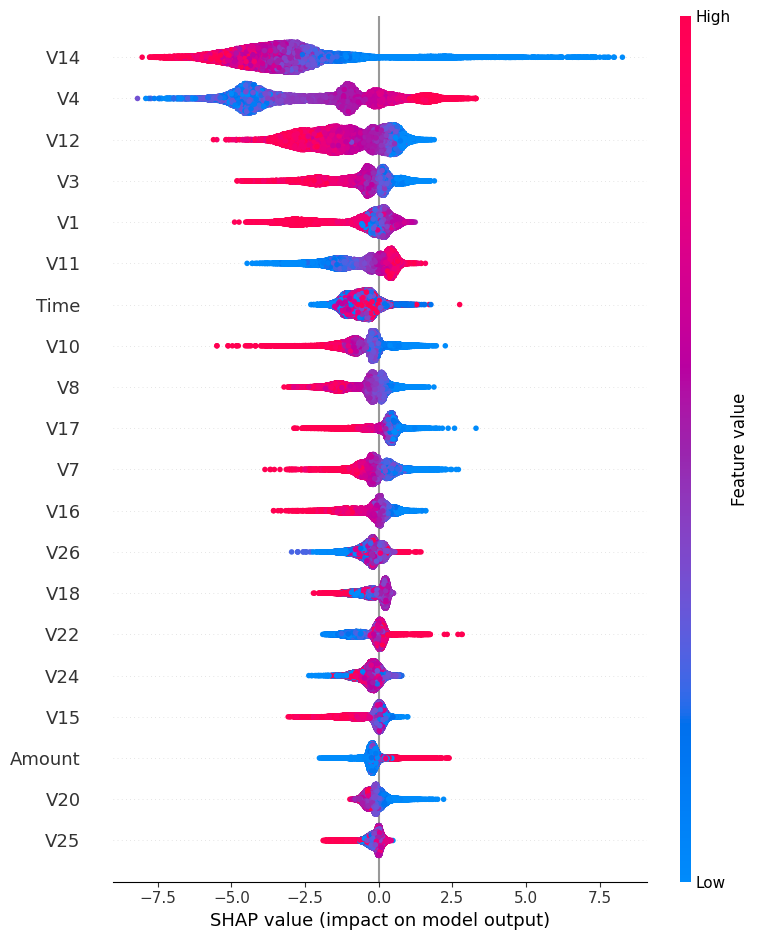

In [32]:
import shap

explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test_scaled)
shap.summary_plot(shap_values, X_test, feature_names=X_test.columns)

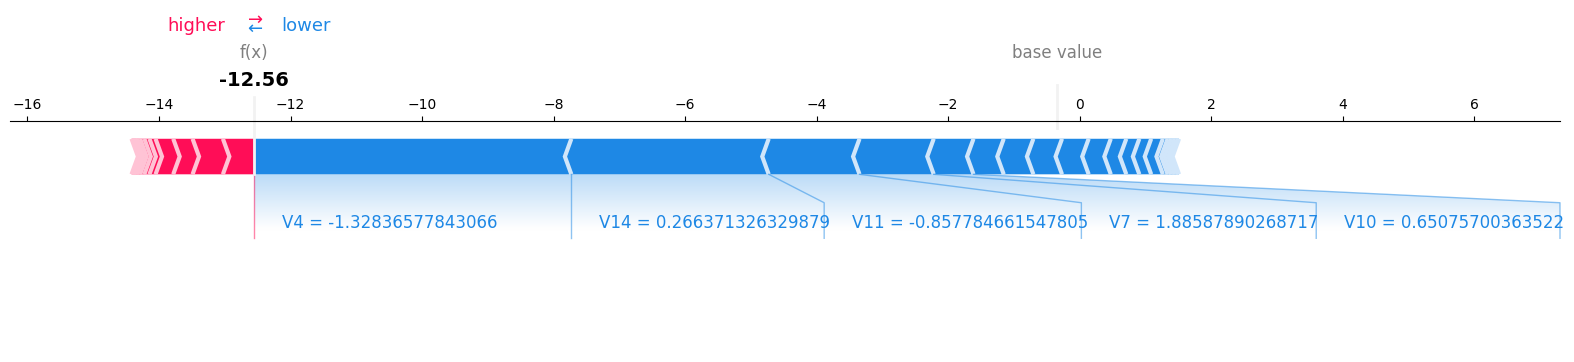

In [33]:
shap.force_plot(explainer.expected_value, shap_values[0], X_test.iloc[0], matplotlib=True)

### Selecting a Flagged Transaction to Explain

In [34]:
fraud_indices = np.where(Y_pred_final_xgb == 1)[0]
print(fraud_indices[:5])  # Here shows a few row positions the model flagged as fraud

[ 165  586  840 1146 2777]


### Individual Prediction Explanation

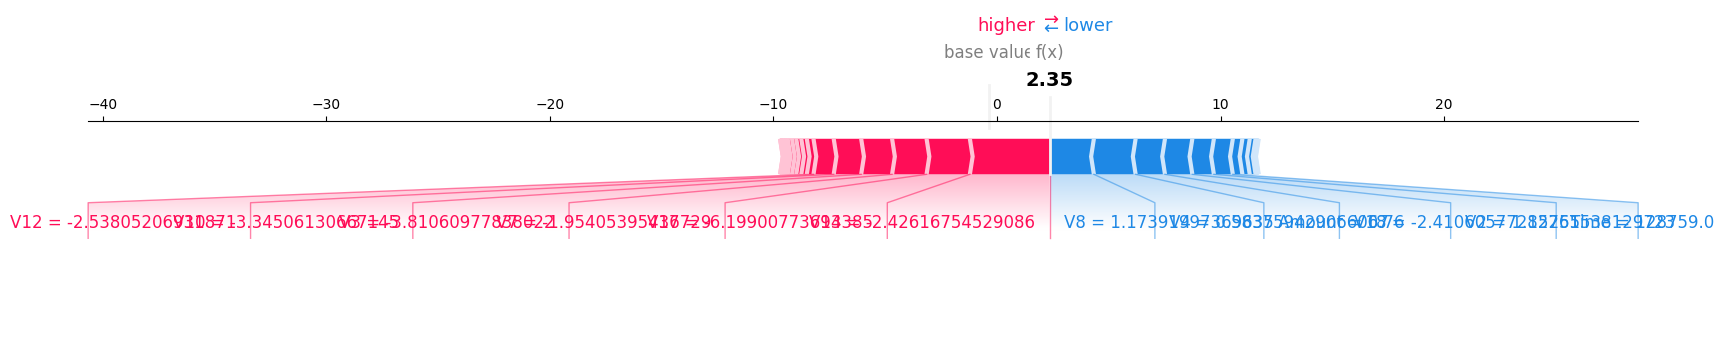

In [35]:
idx = fraud_indices[0] # here it will auto gets first row
shap.force_plot(explainer.expected_value, shap_values[idx], X_test.iloc[idx], matplotlib=True)

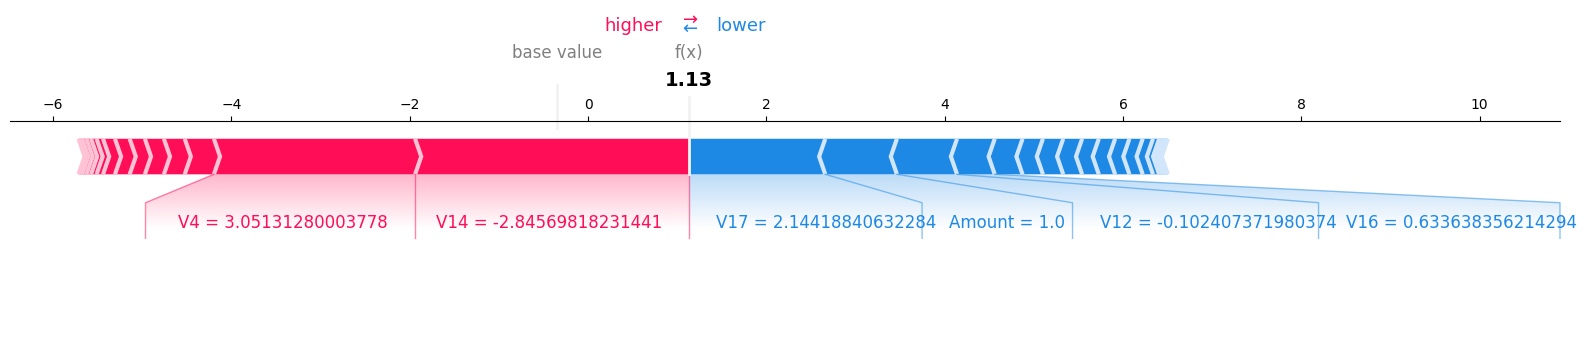

In [37]:
idx = 586  #any number from the list
shap.force_plot(explainer.expected_value, shap_values[idx], X_test.iloc[idx], matplotlib=True)

In [38]:
import joblib

joblib.dump(best_xgb, 'fraud_xgb_model.pkl')
joblib.dump(scaler, 'fraud_scaler.pkl')

['fraud_scaler.pkl']